In [4]:
import matplotlib, matplotlib.pyplot as plt
import stpsf
from astropy.io import fits
import scipy.ndimage as nd

import numpy as np
import glob
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from matplotlib.colors import LogNorm
import random
import astropy

#pour enlever le message de warning : WARNING: VerifyWarning: Card is too long, comment will be truncated. [astropy.io.fits.card]
import warnings
from astropy.io.fits.verify import VerifyWarning
warnings.filterwarnings("ignore", category=VerifyWarning)


In [ ]:
pid = 'P03662'
oid = '004'
path_data = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/'
path_save =  '/home/cperrot/Work/projet/JWST/Target/Calib/sgd/analyse_sgd/'

files = glob.glob(path_data+pid+'/obs'+oid+'/'+pid+'_'+oid+'_REF_*.fits',recursive=False)
files.sort()
files = [files[0]]
print('number of file : ',len(files))

sgd_pattern_x = np.array([0, 1, 1, 0, -1, -1, -1, 0, 1]) # theorical X offset in mas
sgd_pattern_y = np.array([0, 0, -1, -1, -1, 0, 1, 1, 1]) # theorical Y offset in mas

miri = stpsf.setup_sim_to_match_file(files[0])

for i in range(len(files)):
    sgd_psf = fits.open(files[i])[1].data 
    for ox in range(-4,5,1):
        for oy in range(-4,5,1):
            miri.options['source_offset_x'] = sgd_pattern_x[i]*0.01 + ox*0.0005      # scan around theorical sgd X position with +/- 10 step of 0.5 mas
            miri.options['source_offset_y'] = sgd_pattern_y[i]*0.01 + oy*0.0005      # scan around theorical sgd Y position with +/- 10 step of 0.5 mas
            coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=100,oversample=4)
            coron_psf.writeto(path_save+'tmp.fits', overwrite=True)
            obs = fits.open(path_save+'tmp.fits')[1].data  
            imp.save_fits(obs,path_save+pid+'/obs'+oid+'/'+pid+'_'+oid+'_REF_'+str(i)+'_x='+str(ox*0.5)+'_y='+str(oy*0.5)+'.fits')



number of file :  1


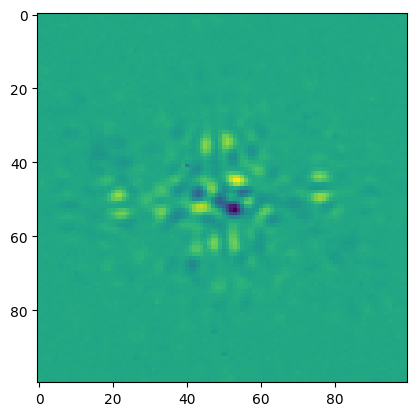

simu : 0.010045312667267409
obs  : 11001.75


In [38]:

pid = 'P03662'
oid = '004'
oidb = '005'
path_data = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/'
path_save =  '/home/cperrot/Work/projet/JWST/Target/Calib/sgd/analyse_sgd/'
dim = 100

files = glob.glob(path_data+pid+'/obs'+oid+'/'+pid+'_'+oid+'_REF_*.fits',recursive=False)
files.sort()
files = [files[1]]
print('number of file : ',len(files))
files_b = glob.glob(path_data+pid+'/obs'+oidb+'/'+pid+'_'+oidb+'_REF_*_background_dither?_cal.fits',recursive=False)
files_b.sort()
bkg = np.minimum(fits.open(files_b[0])[1].data, fits.open(files_b[1])[1].data)
obs = fits.open(files[0]) 
if obs[0].header['FILTER'] == 'F1065C': x0, y0 = 120.25, 112.03 # lambda en m
if obs[0].header['FILTER'] == 'F1140C': x0, y0 = 119.77, 112.16 # lambda en m
if obs[0].header['FILTER'] == 'F1550C': x0, y0 = 119.71, 113.28 # lambda en m
obs = obs[1].data
obs_clean = obs - bkg
obs_clean = imp.clean_image_nan(obs_clean)
obs_clean = nd.shift(obs_clean,[dim/2-y0,dim/2-x0])[0:dim,0:dim]


files_simu = glob.glob(path_save+pid+'/obs'+oid+'/'+pid+'_'+oid+'_REF_*.fits',recursive=False)
files_simu.sort()

diff = np.ndarray([81,100,100])
for i in range(len(files_simu)):
    sgd_simu = fits.open(files_simu[i])[0].data
    diff[i,:,:] = (sgd_simu/np.sum(sgd_simu))-(obs_clean/np.sum(obs_clean))

imp.save_fits(diff,path_save+pid+'/obs'+oid+'/'+pid+'_'+oid+'_DIFF.fits')
plt.imshow((sgd_simu/np.sum(sgd_simu))-(obs_clean/np.sum(obs_clean)))
plt.show()

imp.save_fits(sgd_simu/np.sum(sgd_simu),path_save+pid+'/obs'+oid+'/'+pid+'_'+oid+'_test_simu.fits')
imp.save_fits(obs_clean/np.sum(obs_clean),path_save+pid+'/obs'+oid+'/'+pid+'_'+oid+'_test_obs.fits')

print("simu :",np.sum(sgd_simu))
print("obs  :",np.sum(obs_clean))


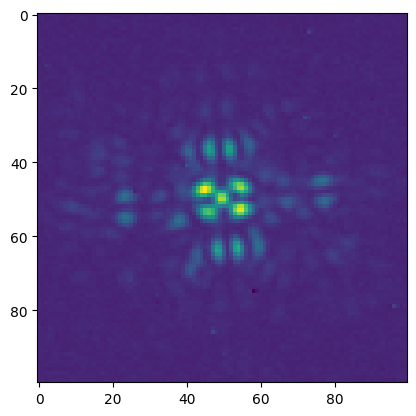

['/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs004/P03662_004_REF_CD23_9765_dither1_cal.fits']
(81, 100, 100)


In [31]:
plt.imshow(obs_clean)
plt.show()
print(files)
print(np.shape(diff))